# Orthodontic Patient Flow & Offer Analytics
### Bright Smile Dental Clinic, Bisha, Saudi Arabia · January 2025 to November 2026

**Author:** Nura Jehad Alsaloul · MSc Data Science

This notebook analyses about two years of real orthodontic-clinic data: **7,224 appointments, 900 patients and 3,940 payments**. It answers four business questions:

1. **Growth:** Is the orthodontic clinic growing, and where does the growth come from?
2. **No-shows:** About 1 in 5 appointments is missed. What predicts a no-show?
3. **New patients:** How many new patients start treatment, and how well do examinations convert into treatment?
4. **Case study:** Did the change in the 2026 National Day offer affect new-patient starts and revenue?

> **Privacy.** The data was exported from the clinic's practice-management system and anonymised before analysis (see `src/anonymize.py`). Names, phone numbers, national IDs, file numbers, exact birth dates, staff names and free-text notes were removed. Patients carry pseudonymous codes only. Published with the clinic's permission.

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

# Find the data file: works locally (repo folder) and on Google Colab.
CANDIDATES = [Path('../data/ortho_clinic_anonymized.xlsx'),
              Path('data/ortho_clinic_anonymized.xlsx'),
              Path('ortho-retention-analytics/data/ortho_clinic_anonymized.xlsx'),
              Path('ortho_clinic_anonymized.xlsx')]
DATA = next((p for p in CANDIDATES if p.exists()), None)
if DATA is None:
    # On Colab: clone the repo first, e.g.  !git clone https://github.com/Nura-Alsaloul/ortho-retention-analytics
    raise FileNotFoundError('Data file not found. Clone the repo or upload ortho_clinic_anonymized.xlsx')

FIG = DATA.parent.parent / 'figures'
FIG.mkdir(exist_ok=True)

# Chart style: one consistent, colour-blind-safe palette
C2025, C2026 = '#2a78d6', '#eb6834'      # blue = 2025, orange = 2026
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': GRID, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False, 'figure.dpi': 110,
})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

## 2. Load the data

In [2]:
appts = pd.read_excel(DATA, sheet_name='appointments')
patients = pd.read_excel(DATA, sheet_name='patients')
payments = pd.read_excel(DATA, sheet_name='payments')

print(f'Appointments: {len(appts):,} | Patients: {patients.patient_id.nunique():,} | Payments: {len(payments):,}')
print('Period:', appts.start.min().date(), 'to', appts.start.max().date())
appts.head()

Appointments: 7,224 | Patients: 900 | Payments: 3,940
Period: 2025-01-01 to 2026-11-18


,appointment_id,patient_id,start,end,room,appointment_type,status,checked_in_at,seen_at,wait_seconds,chair_seconds,booked_at,cancellation_category,lead_time_days,age_band,nationality_group
0,1,P0001,2025-01-01 15:15:00,2025-01-01 15:30:00,Clinic 6,Routine treatment,Completed,2025-01-01 14:36:42,2025-01-01 14:42:44,361.0,605.0,2024-12-31 11:23:29,NaN,1.160775,<13,Saudi
1,2,P0002,2025-01-01 16:00:00,2025-01-01 16:15:00,Clinic 6,Routine treatment,No-show,NaT,NaT,NaN,NaN,2024-12-02 17:02:47,NaN,29.956400,18-24,Saudi
2,3,P0003,2025-01-01 16:15:00,2025-01-01 16:30:00,Clinic 6,Routine treatment,Completed,2025-01-01 16:02:44,2025-01-01 16:03:26,41.0,1039.0,2024-12-03 16:06:34,NaN,29.005856,25-34,Saudi
3,4,P0004,2025-01-01 16:30:00,2025-01-01 16:45:00,Clinic 6,Routine treatment,Completed,2025-01-01 16:28:11,2025-01-01 16:49:53,1301.0,113.0,2024-12-03 17:09:27,NaN,28.972604,18-24,Saudi
4,5,P0006,2025-01-01 17:00:00,2025-01-01 17:30:00,Clinic 6,Examination,Completed,NaT,2025-01-01 16:21:40,NaN,976.0,2025-01-01 16:14:44,NaN,0.031435,18-24,Saudi


## 3. Cleaning decisions

Each decision is documented so the analysis can be reproduced:

| Issue | Decision |
|---|---|
| In 2025 most adjustment visits were recorded as **"Routine treatment"**. From 2026 the doctor records them as **"Follow-up"** (confirmed with clinic staff). | Merge both into one category, **Follow-up visit**, so the years are comparable. |
| **"Separators placement"** appears only in 2026. It is a new clinical step about 5 days *before* braces placement. | Keep it as its own step. It is **not** counted as a placement. |
| Future appointments (status *Booked* / *Confirmed*) have no outcome yet. | Exclude them from attendance analysis. |
| Data ends on 18 Nov 2026. | Compare years over the **same calendar window** (1 Jan to 18 Nov). |
| Refunded payments | Excluded from revenue. |

In [3]:
appts['visit_type'] = appts.appointment_type.replace({'Routine treatment': 'Follow-up visit',
                                                      'Follow-up (adjustment)': 'Follow-up visit'})
appts['year'] = appts.start.dt.year
appts['month'] = appts.start.dt.month

# Appointments with a known outcome
past = appts[appts.status.isin(['Completed', 'No-show', 'Cancelled', 'Late'])].copy()
past['no_show'] = past.status.eq('No-show')

# Same calendar window in both years: 1 Jan to 18 Nov
same_window = (past.month < 11) | ((past.month == 11) & (past.start.dt.day <= 18))
pw = past[same_window]

payments = payments[~payments.refunded].copy()
print(f'Appointments with an outcome: {len(past):,}')

Appointments with an outcome: 7,192


## 4. Growth: where does it come from?

In [4]:
summary = pw.groupby('year').agg(appointments=('appointment_id', 'size'),
                                 active_patients=('patient_id', 'nunique'),
                                 no_show_rate=('no_show', 'mean'))
summary['no_show_rate'] = (summary.no_show_rate * 100).round(1)
summary.loc['change %'] = ((summary.loc[2026] / summary.loc[2025] - 1) * 100).round(1)
summary

,appointments,active_patients,no_show_rate
year,,,
2025,2891.0,539.0,21.8
2026,3838.0,621.0,18.7
change %,32.8,15.2,-14.2


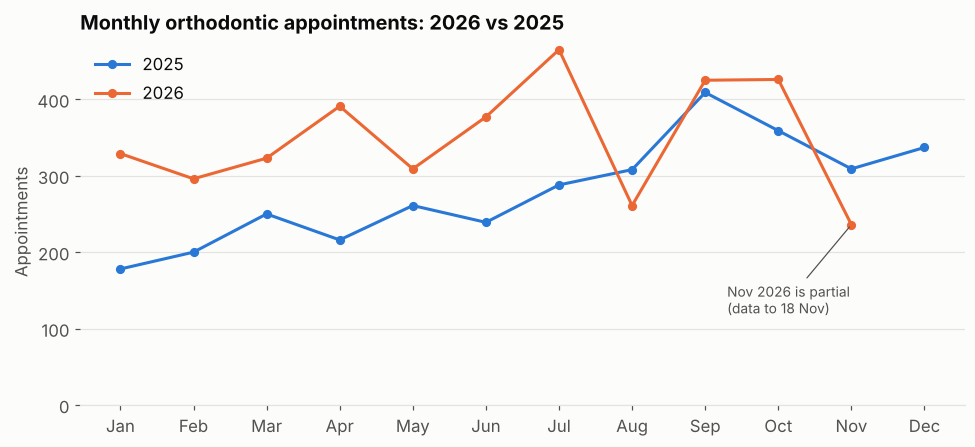

In [5]:
monthly = past.groupby(['year', 'month']).size().unstack(0)
labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(monthly.index, monthly[2025], color=C2025, lw=2, marker='o', ms=5, label='2025')
ax.plot(monthly.index, monthly[2026], color=C2026, lw=2, marker='o', ms=5, label='2026')
ax.set_xticks(range(1, 13), labels)
ax.set_ylim(0)
ax.set_title('Monthly orthodontic appointments: 2026 vs 2025')
ax.set_ylabel('Appointments')
ax.annotate('Nov 2026 is partial\n(data to 18 Nov)', xy=(11, monthly.loc[11, 2026]), xytext=(9.3, 120),
            fontsize=9, color=MUTED, arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.legend(loc='upper left')
save(fig, '01_monthly_appointments')

In [6]:
# Which visit types grew?
mix = pw[pw.status == 'Completed'].pivot_table(index='visit_type', columns='year',
                                               values='appointment_id', aggfunc='size').fillna(0).astype(int)
mix['change %'] = ((mix[2026] / mix[2025].replace(0, np.nan) - 1) * 100).round(0)
mix.sort_values(2026, ascending=False)

year,2025,2026,change %
visit_type,,,
Follow-up visit,1452,2047,41.0
Examination,406,366,-10.0
Braces placement,166,145,-13.0
Retainer,75,98,31.0
Separators placement,0,82,NaN
Other,0,56,NaN
Consultation,6,1,-83.0
Emergency,0,1,NaN
Cleaning,1,0,-100.0


**Finding 1:** Appointments grew by about **33%** over the same window. Almost all of the growth comes from **follow-up visits of existing patients**. Completed **examinations (-10%)** and **braces placements (-13%)** fell, so the clinic is busier with current patients but is bringing in **fewer new patients**.

## 5. No-shows: what predicts a missed appointment?

                mean  size
lead_band                 
0-1 day     0.073651  2186
2-7 days    0.218776  1225
8-14 days   0.185430   302
15-30 days  0.270652   920
31-60 days  0.267793  2487
60+ days    0.304348    69


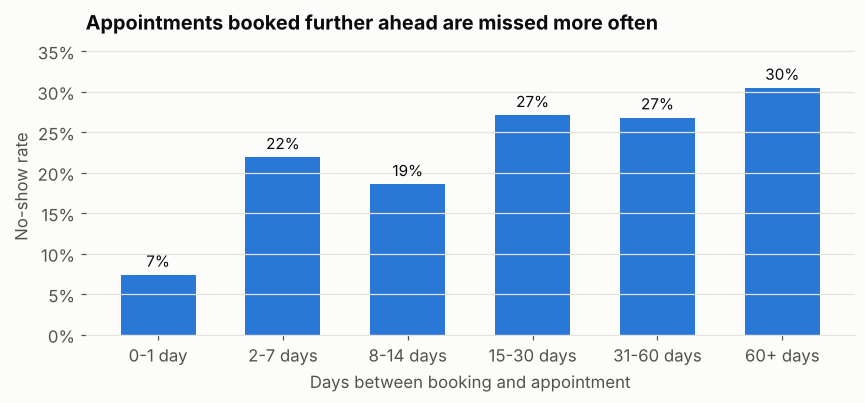

In [7]:
def rate_bar(series, title, xlabel, name, color=C2025):
    fig, ax = plt.subplots(figsize=(8, 3.8))
    bars = ax.bar(series.index.astype(str), series.values, color=color, width=0.6)
    ax.bar_label(bars, labels=[f'{v:.0%}' for v in series.values], padding=3, fontsize=10, color=INK)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_ylim(0, max(series.values) * 1.2)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel('No-show rate')
    save(fig, name)

# 5a. Booking lead time: days between booking and the appointment
past['lead_band'] = pd.cut(past.lead_time_days, [-1, 1, 7, 14, 30, 60, 9999],
                           labels=['0-1 day', '2-7 days', '8-14 days', '15-30 days', '31-60 days', '60+ days'])
lead = past.groupby('lead_band', observed=True).no_show.agg(['mean', 'size'])
print(lead)
rate_bar(lead['mean'], 'Appointments booked further ahead are missed more often',
         'Days between booking and appointment', '02_noshow_by_lead_time')

             mean  size
history                
0        0.125471  3188
1        0.192883  1405
2-3      0.254613  1355
4+       0.325563  1244


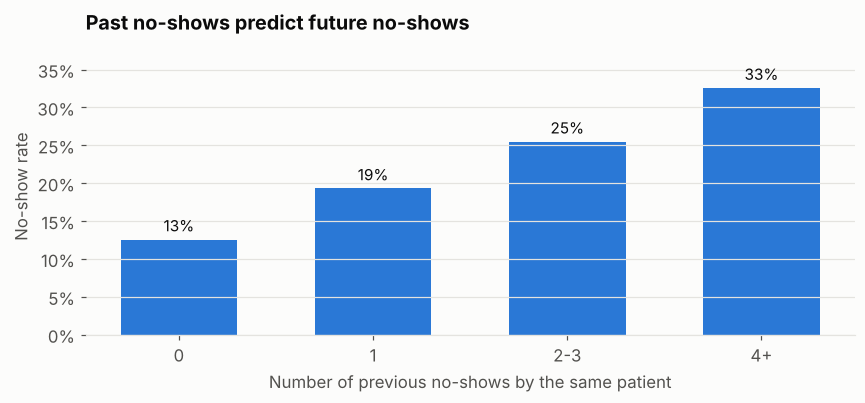

In [8]:
# 5b. A patient's own no-show history (only appointments BEFORE this one are counted)
past = past.sort_values('start')
past['prior_no_shows'] = past.groupby('patient_id').no_show.transform(lambda s: s.shift().cumsum()).fillna(0)
past['history'] = pd.cut(past.prior_no_shows, [-1, 0, 1, 3, 999], labels=['0', '1', '2-3', '4+'])
hist = past.groupby('history', observed=True).no_show.agg(['mean', 'size'])
print(hist)
rate_bar(hist['mean'], 'Past no-shows predict future no-shows',
         'Number of previous no-shows by the same patient', '03_noshow_by_history')

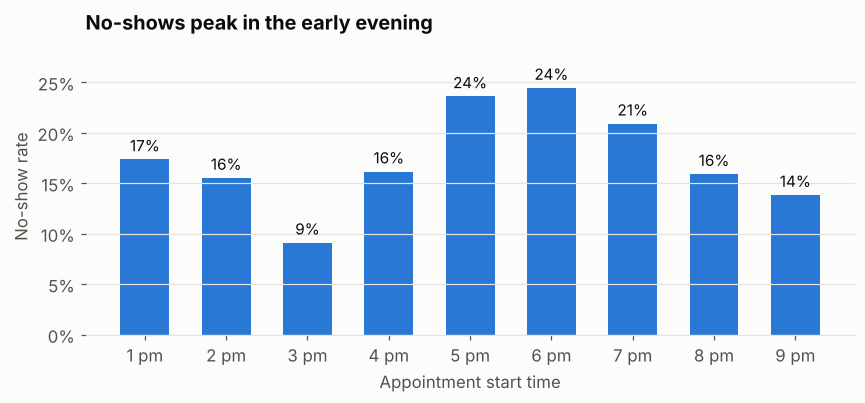

In [9]:
# 5c. Time of day (main working hours only)
hour = past[past.start.dt.hour.between(13, 21)].groupby(past.start.dt.hour).no_show.mean()
hour.index = [f'{h-12} pm' if h > 12 else f'{h} pm' for h in hour.index]
rate_bar(hour, 'No-shows peak in the early evening', 'Appointment start time', '04_noshow_by_hour')

**Finding 2:** About 1 in 5 appointments is missed (**21% in 2025 to 18.7% in 2026**). Two signals stand out:

* **Lead time:** appointments booked the same or next day are missed **7%** of the time. Appointments booked 15 to 60 days ahead, which is typical for monthly adjustments, are missed **~27%** of the time.
* **History:** a patient with no previous no-shows misses **12.5%** of appointments. A patient with 4 or more previous no-shows misses **32.6%**.

**Recommendation:** send a confirmation message **2 days before** every appointment booked more than a week ahead. Give patients with 2 or more past no-shows a **phone call** on top of the message.

## 6. New patients and conversion

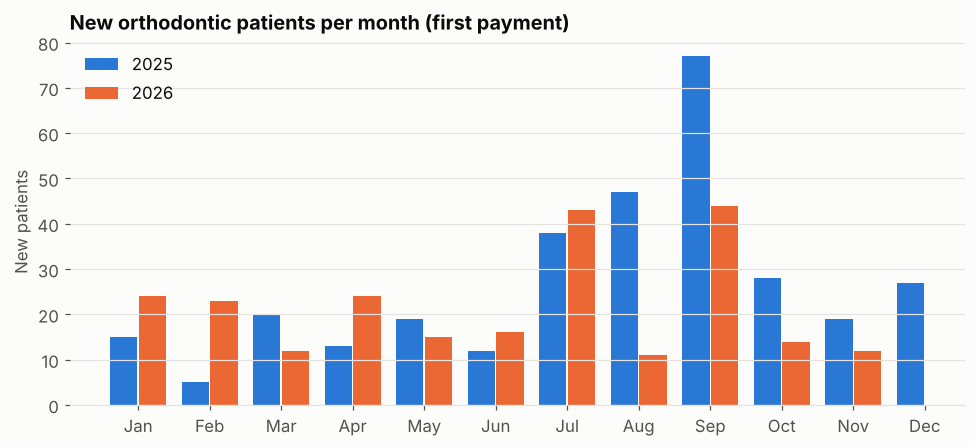

patient_first_payment,1,2,3,4,5,6,7,8,9,10,11,12
patient_first_payment,,,,,,,,,,,,
2025,15.0,5.0,20.0,13.0,19.0,12.0,38.0,47.0,77.0,28.0,19.0,27.0
2026,24.0,23.0,12.0,24.0,15.0,16.0,43.0,11.0,44.0,14.0,12.0,NaN


In [10]:
# A new patient = the patient's first-ever payment at the clinic falls in that month
first_pay = payments.groupby('patient_id').patient_first_payment.first()
new_by_month = first_pay.groupby([first_pay.dt.year, first_pay.dt.month]).size().unstack(0)
new_by_month = new_by_month.loc[:, [2025, 2026]].reindex(range(1, 13))

fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(1, 13); w = 0.38
ax.bar(x - w/2 - 0.01, new_by_month[2025], width=w, color=C2025, label='2025')
ax.bar(x + w/2 + 0.01, new_by_month[2026], width=w, color=C2026, label='2026')
ax.set_xticks(x, labels)
ax.set_title('New orthodontic patients per month (first payment)')
ax.set_ylabel('New patients'); ax.legend(loc='upper left')
save(fig, '05_new_patients_monthly')
new_by_month.T

## 7. Case study: the National Day offer, 2025 vs 2026

The clinic runs a National Day offer every year. **The offer terms changed in 2026:**

| | 2025 offer (from 28 Aug) | 2026 offer (from 1 Sep) |
|---|---|---|
| **One jaw** | 295 SAR down + 200/month for **8 months** + 295 retainer = **2,190 SAR total** | 396 SAR down + 200/month **until treatment ends** + 296 retainer |
| **Both jaws** | 590 SAR down + 250/month for **12 months** + 590 retainer = **4,180 SAR total** | 696 SAR down + 250/month **until treatment ends** + 592 retainer |

The 2026 offer earns more per patient but has **no fixed total**. Each offer is measured from its start date to 31 October.

In [11]:
OFFERS = {2025: ('2025-08-28', '2025-11-01', {295, 590}),
          2026: ('2026-09-01', '2026-11-01', {396, 696})}

rows = {}
for year, (start, end, down_payments) in OFFERS.items():
    lo, hi = pd.Timestamp(start), pd.Timestamp(end)
    in_window = payments[(payments.paid_at >= lo) & (payments.paid_at < hi)]
    new_ids = first_pay[(first_pay >= lo) & (first_pay < hi)].index
    new_pay = payments[payments.patient_id.isin(new_ids)]
    started = new_pay[~new_pay.is_diagnostic_fee].patient_id.nunique()
    # first treatment (non-examination) payment of each new patient
    first_trt = new_pay[~new_pay.is_diagnostic_fee].sort_values('paid_at').groupby('patient_id').first()
    offer_starts = first_trt[first_trt.amount_sar.round().isin(down_payments)]
    exam_payers = in_window[in_window.is_diagnostic_fee].patient_id.nunique()
    rows[year] = {
        'New patients (first payment)': len(new_ids),
        'Paid examination fee': exam_payers,
        'Started treatment': started,
        'Did not start after exam': exam_payers - started,
        'Paid the offer down payment': len(offer_starts),
        'Revenue from new patients (SAR)': round(new_pay[(new_pay.paid_at >= lo) & (new_pay.paid_at < hi)].amount_sar.sum()),
        'Total ortho revenue in window (SAR)': round(in_window.amount_sar.sum()),
    }
funnel = pd.DataFrame(rows)
funnel['change %'] = ((funnel[2026] / funnel[2025] - 1) * 100).round(0)
funnel

,2025,2026,change %
New patients (first payment),120,58,-52.0
Paid examination fee,114,71,-38.0
Started treatment,97,30,-69.0
Did not start after exam,17,41,141.0
Paid the offer down payment,58,19,-67.0
Revenue from new patients (SAR),61394,20645,-66.0
Total ortho revenue in window (SAR),123979,100788,-19.0


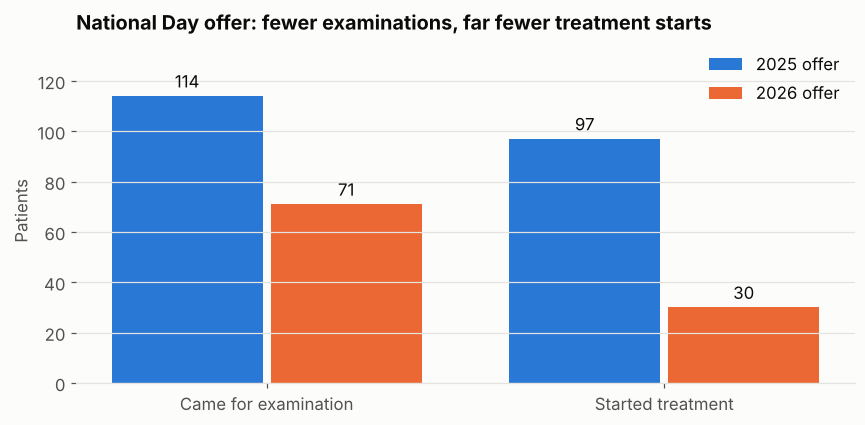

2025: 85% of examined patients started treatment
2026: 42% of examined patients started treatment


In [12]:
steps = ['Paid examination fee', 'Started treatment']
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(steps)); w = 0.38
b1 = ax.bar(x - w/2 - 0.01, funnel.loc[steps, 2025], width=w, color=C2025, label='2025 offer')
b2 = ax.bar(x + w/2 + 0.01, funnel.loc[steps, 2026], width=w, color=C2026, label='2026 offer')
ax.bar_label(b1, padding=3); ax.bar_label(b2, padding=3)
ax.set_xticks(x, ['Came for examination', 'Started treatment'])
ax.set_ylim(0, funnel.loc[steps, 2025].max() * 1.2)
ax.set_title('National Day offer: fewer examinations, far fewer treatment starts')
ax.set_ylabel('Patients'); ax.legend()
save(fig, '06_offer_funnel')

for y in (2025, 2026):
    print(f"{y}: {funnel.loc['Started treatment', y] / funnel.loc['Paid examination fee', y]:.0%} of examined patients started treatment")

### Did the higher price per patient make up for fewer patients?
The full contract value of each year's offer starters, assuming every patient completes treatment:

In [13]:
def contract_value(year, jaws, months):
    if year == 2025:
        return 295 + 8*200 + 295 if jaws == 1 else 590 + 12*250 + 590
    return 396 + months*200 + 296 if jaws == 1 else 696 + months*250 + 592

# Starters by offer type, identified from the down-payment amount
starters = {}
for y, (start, end, dps) in OFFERS.items():
    lo, hi = pd.Timestamp(start), pd.Timestamp(end)
    new_ids = first_pay[(first_pay >= lo) & (first_pay < hi)].index
    np_ = payments[payments.patient_id.isin(new_ids) & ~payments.is_diagnostic_fee]
    first_trt = np_.sort_values('paid_at').groupby('patient_id').amount_sar.first().round()
    one, both = sorted(dps)
    starters[y] = {1: int((first_trt == one).sum()), 2: int((first_trt == both).sum())}
print('Offer starters (jaws: patients):', starters)

scen = pd.DataFrame({m: {y: sum(n * contract_value(y, j, m) for j, n in starters[y].items()) for y in (2025, 2026)}
                     for m in (12, 18, 24)}).T
scen.index.name = 'Treatment length (months)'
scen['2026 as % of 2025'] = (scen[2026] / scen[2025] * 100).round(0)
scen

Offer starters (jaws: patients): {2025: {1: 8, 2: 50}, 2026: {1: 3, 2: 16}}


,2025,2026,2026 as % of 2025
Treatment length (months),,,
12,226520,77884,34.0
18,226520,105484,47.0
24,226520,133084,59.0


In [14]:
# Estimated patients lost: assume the share of clinically ineligible patients is the same in both years
base_non_start = funnel.loc['Did not start after exam', 2025] / funnel.loc['Paid examination fee', 2025]
exp_ineligible_2026 = base_non_start * funnel.loc['Paid examination fee', 2026]
lost = funnel.loc['Did not start after exam', 2026] - exp_ineligible_2026
print(f'2025 non-start rate (baseline, mostly ineligible patients): {base_non_start:.0%}')
print(f'Estimated eligible patients who did not start in 2026: ~{lost:.0f}')
print(f'Potential lost contract value at the 2025 both-jaws price: ~{lost * 4180:,.0f} SAR')

2025 non-start rate (baseline, mostly ineligible patients): 15%
Estimated eligible patients who did not start in 2026: ~30
Potential lost contract value at the 2025 both-jaws price: ~127,123 SAR


**Finding 3 (case study):** After the offer changed to open-ended instalments:

* New patients fell by about **half**, and **treatment starts fell by about two thirds** (97 to 30).
* The biggest drop is **after the examination**: 85% of examined patients started treatment in 2025, against 42% in 2026. Clinic staff report that most patients who decline mention the **open-ended instalments**. An open-ended plan hides the total cost, which makes patients hesitate.
* Even if treatment lasts 24 months, the 2026 starters are worth only about **59%** of the 2025 starters. **The higher price per patient does not make up for the lost volume.**
* Using 2025's non-start rate as the baseline for ineligible patients, about **30 eligible patients** did not start in 2026.

**Caveat:** this is an observational before/after comparison. It shows that the policy change and the drop happened together, not that one caused the other. Competitors, ad spend and seasonality could also contribute. Patients examined in October 2026 may still start in the coming weeks.

**Recommendation:** keep the monthly instalment but **add a cap**, for example *200 SAR/month, maximum 18 months*, so the total is known upfront. Call the patients who were examined in Sep to Oct 2026 but did not start, to confirm their reasons and re-offer the capped plan.

## 8. Summary for clinic management

| # | Finding | Action |
|---|---|---|
| 1 | Appointments grew 33%, driven by follow-ups. New patients fell. | Shift marketing toward **examination bookings**. |
| 2 | 1 in 5 appointments is missed. Risk rises with lead time and past no-shows. | **2-day confirmation** for far-ahead bookings, plus calls for repeat no-show patients. |
| 3 | The open-ended 2026 offer coincided with treatment starts falling ~69%. | **Cap the instalments** and follow up with examined patients who did not start. |

*Tools: Python (pandas, matplotlib) · Data: Dentolize exports, anonymised.*